# Hidden condition states: filtering and smoothing

**Notebook author: Ziad Mosalam**  
Companion to *Bayesian Methods for Autonomous Robotics and Intelligent Infrastructure Systems* by Khalid M. Mosalam.

This notebook supports the **Hidden Markov Models** chapter. A sensor records a noisy condition indicator while the system moves through three latent condition states. We compare what can be inferred at the current inspection with what can be reconstructed after later inspections are available.

All states and observations are simulated. The three classes are named **low**, **moderate**, and **high** condition index. They are not calibrated structural damage classes or safety categories.

Run all cells from the `notebooks/` directory. The final figure appears inline and is exported to `../figures/condition-monitoring.pdf` and `.png`.

In [1]:
from itertools import product
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.special import logsumexp
from scipy.stats import norm

plt.style.use('book.mplstyle')
figures = Path('../figures')
figures.mkdir(exist_ok=True)

BLUE, GOLD, TEAL, INK = '#003262', '#B17A00', '#247C86', '#30363B'
state_names = ['Low', 'Moderate', 'High']
state_colors = [TEAL, GOLD, BLUE]

## 1. A transparent condition model

Let $S_t\in\{0,1,2\}$ be the hidden condition state and $Y_t$ the standardized sensor indicator at inspection $t$. The transition probabilities are
\[
A_{ij}=\Pr(S_t=j\mid S_{t-1}=i),\qquad
A=\begin{pmatrix}
0.965&0.035&0\\
0&0.950&0.050\\
0&0&1
\end{pmatrix}.
\]
This model allows progressive changes and no recovery. The high state is absorbing. There is no intervention in the simulation; a repair model would require different transitions or action-dependent dynamics.

Conditional observations are independent given the state sequence:
\[
Y_t\mid S_t=j\sim\mathcal N(m_j,0.85^2),\qquad
(m_0,m_1,m_2)=(0,1.3,2.6).
\]
The distributions overlap substantially. One large sensor value therefore does not identify the high state by itself. We use $\Pr(S_0)=(0.9,0.1,0)$ and keep the transition and emission parameters known so the notebook isolates state inference rather than parameter fitting.

In [2]:
transition = np.array([
    [0.965, 0.035, 0.000],
    [0.000, 0.950, 0.050],
    [0.000, 0.000, 1.000],
])
initial = np.array([0.9, 0.1, 0.0])
emission_mean = np.array([0.0, 1.3, 2.6])
emission_sd = np.array([0.85, 0.85, 0.85])
inspection_count = 100

# Separate random streams keep the latent path fixed if observation noise is changed.
state_rng = np.random.default_rng(2026)
observation_rng = np.random.default_rng(2027)
hidden = np.empty(inspection_count, dtype=int)
hidden[0] = state_rng.choice(3, p=initial)
for t in range(1, inspection_count):
    hidden[t] = state_rng.choice(3, p=transition[hidden[t - 1]])
observations = observation_rng.normal(emission_mean[hidden], emission_sd[hidden])
change_times = np.flatnonzero(np.diff(hidden)) + 1

np.testing.assert_allclose(transition.sum(axis=1), 1)
assert np.all(transition >= 0)
print('Synthetic state changes at inspections:', change_times.tolist())
print('Time in each state:', dict(zip(state_names, np.bincount(hidden, minlength=3).tolist())))

Synthetic state changes at inspections: [10, 65]
Time in each state: {'Low': 10, 'Moderate': 55, 'High': 35}


## 2. Filtering uses information available now

Write $b_j(y_t)=p(y_t\mid S_t=j)$. The filtered probabilities obey
\[
\alpha_t(j)\propto b_j(y_t)\sum_i\alpha_{t-1}(i)A_{ij},
\qquad \sum_j\alpha_t(j)=1.
\]
For $t=0$, replace the sum by the initial probabilities. We evaluate the recursion in log space. The logarithm of each normalization constant is also retained; their sum is the log evidence $\log p(y_{0:T-1})$.

The zeros in $A$ encode impossible transitions. They remain $-\infty$ in log space; no numerical floor quietly changes the model.

In [3]:
def log_probabilities(probabilities):
    values = np.full_like(probabilities, -np.inf, dtype=float)
    np.log(probabilities, out=values, where=probabilities > 0)
    return values

def forward_filter(data, initial, transition):
    log_initial = log_probabilities(initial)
    log_transition = log_probabilities(transition)
    log_emission = norm.logpdf(
        np.asarray(data)[:, None], emission_mean[None, :], emission_sd[None, :]
    )
    log_filtered = np.empty_like(log_emission)
    log_scales = np.empty(len(data))

    log_joint = log_initial + log_emission[0]
    log_scales[0] = logsumexp(log_joint)
    log_filtered[0] = log_joint - log_scales[0]
    for t in range(1, len(data)):
        log_prediction = logsumexp(log_filtered[t - 1, :, None] + log_transition, axis=0)
        log_joint = log_prediction + log_emission[t]
        log_scales[t] = logsumexp(log_joint)
        log_filtered[t] = log_joint - log_scales[t]
    return log_filtered, log_scales, log_emission

log_filtered, log_scales, log_emission = forward_filter(observations, initial, transition)
filtered = np.exp(log_filtered)
log_evidence = float(log_scales.sum())
print(f'Log evidence for the simulated observation sequence: {log_evidence:.3f}')

Log evidence for the simulated observation sequence: -139.337


## 3. Smoothing also uses later observations

The backward message satisfies
\[
\beta_t(i)=\sum_j A_{ij}b_j(y_{t+1})\beta_{t+1}(j),\qquad \beta_{T-1}(i)=1.
\]
Multiplying this message by the filtering result gives
\[
\Pr(S_t=j\mid y_{0:T-1})\propto\alpha_t(j)\beta_t(j).
\]
Below, backward messages are divided by the corresponding forward normalization constants to keep their scale manageable. Normalizing the final products gives exactly the same smoothed probabilities as the unscaled equations.

Smoothing is retrospective. It must not be portrayed as an online estimator that knew future measurements. Later evidence can shift the inferred transition time earlier; smoothing need not reduce entropy at every individual inspection in every realized sequence.

In [4]:
def backward_smoother(log_filtered, log_scales, log_emission, transition):
    log_transition = log_probabilities(transition)
    log_backward = np.zeros_like(log_emission)
    for t in range(len(log_emission) - 2, -1, -1):
        log_backward[t] = logsumexp(
            log_transition + log_emission[t + 1][None, :] + log_backward[t + 1][None, :],
            axis=1,
        ) - log_scales[t + 1]
    log_smoothed = log_filtered + log_backward
    log_smoothed -= logsumexp(log_smoothed, axis=1, keepdims=True)
    return np.exp(log_smoothed), log_backward

smoothed, log_backward = backward_smoother(
    log_filtered, log_scales, log_emission, transition
)

## 4. Independent checks

For four observations there are only $3^4=81$ possible state paths. We explicitly enumerate their joint probabilities and compare the resulting marginal probabilities with forward-backward inference. This tests the recursion against a different calculation. We also reconstruct the evidence from the backward messages and check that filtering and smoothing agree at the final inspection, where no future observations remain.

In [5]:
np.testing.assert_allclose(filtered.sum(axis=1), 1, atol=1e-12)
np.testing.assert_allclose(smoothed.sum(axis=1), 1, atol=1e-12)
np.testing.assert_allclose(filtered[-1], smoothed[-1], atol=1e-12)
assert np.isfinite(log_evidence)

backward_log_evidence = logsumexp(
    log_probabilities(initial) + log_emission[0] + log_backward[0]
) + log_scales[1:].sum()
np.testing.assert_allclose(backward_log_evidence, log_evidence, atol=1e-10)

short_data = np.array([0.2, 1.5, 0.7, 2.0])
short_filter, short_scales, short_emission = forward_filter(short_data, initial, transition)
short_smooth, _ = backward_smoother(short_filter, short_scales, short_emission, transition)
paths = np.array(list(product(range(3), repeat=len(short_data))))
path_log_weights = []
log_transition = log_probabilities(transition)
log_initial = log_probabilities(initial)
for path in paths:
    weight = log_initial[path[0]] + short_emission[0, path[0]]
    for t in range(1, len(short_data)):
        weight += log_transition[path[t - 1], path[t]] + short_emission[t, path[t]]
    path_log_weights.append(weight)
path_log_weights = np.array(path_log_weights)
enumerated_evidence = logsumexp(path_log_weights)
path_weights = np.exp(path_log_weights - enumerated_evidence)
enumerated_marginals = np.array([
    [path_weights[paths[:, t] == state].sum() for state in range(3)]
    for t in range(len(short_data))
])
np.testing.assert_allclose(short_smooth, enumerated_marginals, atol=1e-12)
np.testing.assert_allclose(short_scales.sum(), enumerated_evidence, atol=1e-12)
print('Normalization, terminal agreement, forward/backward evidence and 81-path checks passed.')

Normalization, terminal agreement, forward/backward evidence and 81-path checks passed.


## 5. Why the trends look this way

The sensor evidence is noisy, but persistent changes accumulate across inspections. The filter balances that evidence against a transition model that favors remaining in the current state. The smoother can use subsequent measurements to revisit an earlier ambiguous transition. These mechanisms, not a manually drawn trend, produce the probability maps.

The dashed curves on the probability maps mark the known simulated state, not an estimated most-likely path. The heatmap scale is identical for filtering and smoothing. The early low-state duration in this particular seeded realization is not a claim about a typical component lifetime.

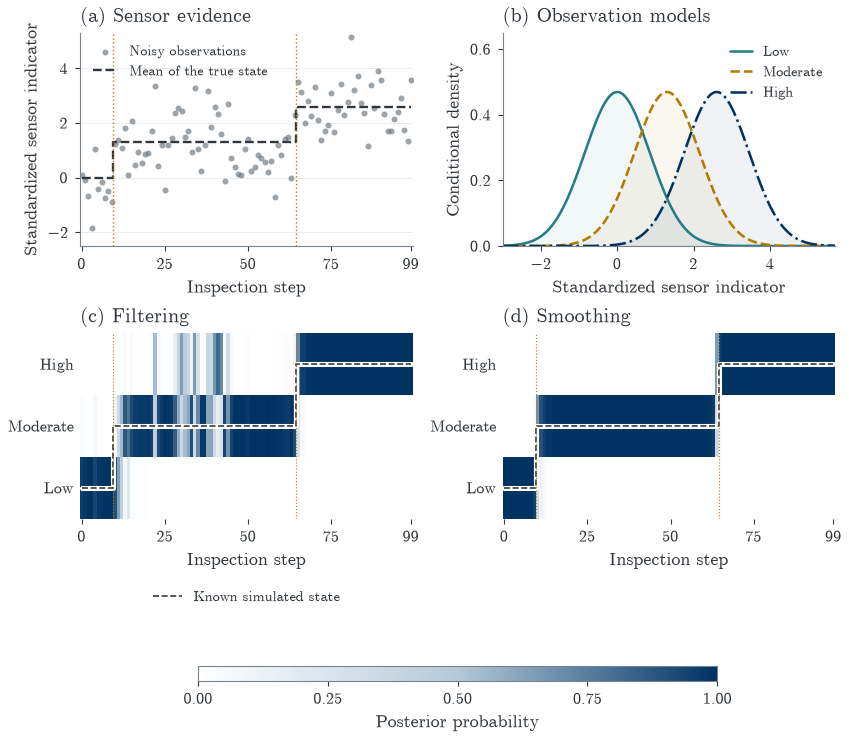

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(6.5, 5.7), layout='constrained',
                         gridspec_kw={'height_ratios': [1.15, 1]})
inspection = np.arange(inspection_count)

ax = axes[0, 0]
ax.scatter(inspection, observations, s=11, color='#69737C', alpha=0.65,
           linewidths=0, label='Noisy observations')
ax.step(inspection, emission_mean[hidden], where='mid', color=INK, ls='--',
        lw=1.3, label='Mean of the true state')
for t in change_times:
    ax.axvline(t - 0.5, color=GOLD, lw=0.8, ls=':', alpha=0.9)
ax.set(title='(a) Sensor evidence', xlabel='Inspection step',
       ylabel='Standardized sensor indicator', xlim=(-0.5, 99.5), ylim=(-2.5, 5.3))
ax.set_xticks([0, 25, 50, 75, 99])
ax.legend(loc='upper left', fontsize=7.8, handlelength=1.8)
ax.grid(axis='y', alpha=0.7)

ax = axes[0, 1]
sensor_grid = np.linspace(-3.0, 5.7, 501)
for state, (name, color) in enumerate(zip(state_names, state_colors)):
    density = norm.pdf(sensor_grid, emission_mean[state], emission_sd[state])
    ax.plot(sensor_grid, density, color=color, ls=['-', '--', '-.'][state], label=name)
    ax.fill_between(sensor_grid, density, color=color, alpha=0.06)
ax.set(title='(b) Observation models', xlabel='Standardized sensor indicator',
       ylabel='Conditional density', xlim=(-3, 5.7), ylim=(0, 0.65))
ax.legend(loc='upper right', fontsize=8, handlelength=1.5)

probability_colors = LinearSegmentedColormap.from_list(
    'berkeley_probability', ['#FFFFFF', '#B4C9D9', BLUE]
)
for ax, probabilities, title in zip(
    axes[1], [filtered, smoothed],
    ['(c) Filtering', '(d) Smoothing'],
):
    image = ax.pcolormesh(np.arange(inspection_count + 1) - 0.5,
                         np.arange(4) - 0.5, probabilities.T,
                         cmap=probability_colors, vmin=0, vmax=1,
                         shading='flat', rasterized=True)
    ax.step(inspection, hidden, where='mid', color='white', lw=2.8)
    ax.step(inspection, hidden, where='mid', color=INK, lw=0.9, ls='--',
            label='Known simulated state')
    for t in change_times:
        ax.axvline(t - 0.5, color=GOLD, lw=0.65, ls=':', alpha=0.9)
    ax.set(title=title, xlabel='Inspection step', xlim=(-0.5, 99.5),
           ylim=(-0.5, 2.5), yticks=[0, 1, 2], yticklabels=state_names)
    ax.set_xticks([0, 25, 50, 75, 99])
    ax.tick_params(axis='y', length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

colorbar = fig.colorbar(image, ax=axes[1], location='bottom', fraction=0.08,
                       shrink=0.75, pad=0.24, aspect=35)
colorbar.set_label('Posterior probability')
axes[1, 0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.32),
                  fontsize=8, frameon=False)
colorbar.set_ticks([0, 0.25, 0.5, 0.75, 1])
fig.savefig(figures / 'condition-monitoring.pdf', metadata={'CreationDate': None, 'ModDate': None})
fig.savefig(figures / 'condition-monitoring.png')
plt.show()

## Interpretation and limits

The forward-backward calculation gives exact state marginals for the stated discrete HMM, up to floating-point precision. It does not establish that this HMM describes a real structure. Its known emission means, independent observation errors, time-homogeneous transitions, and irreversible condition evolution are assumptions that would need validation or modification for field data.

This is one illustrative realization, not a performance benchmark. Posterior probabilities describe uncertainty under the assumed model. The transitions shown in the plot should not be interpreted as physical detection thresholds, verified damage onset times or safety alarms.